In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import math
from pathlib import Path
from scipy.stats import spearmanr

In [4]:
df = pd.read_csv("DAICWOZ_Initial.csv")

In [6]:
# ============================================================
# 1. Basic validation
# ============================================================

required_columns = [
    "Dataset",
    "Gender",
    "PHQ8_Binary",
    "PHQ8_Score",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )

In [7]:
# ============================================================
# 2. Clean the relevant columns
# ============================================================

eda_df = df[required_columns].copy()

eda_df["Dataset"] = (
    eda_df["Dataset"]
    .astype("string")
    .str.strip()
    .str.lower()
)

eda_df["Gender"] = pd.to_numeric(
    eda_df["Gender"],
    errors="coerce"
).astype("Int64")

eda_df["PHQ8_Binary"] = pd.to_numeric(
    eda_df["PHQ8_Binary"],
    errors="coerce"
).astype("Int64")

eda_df["PHQ8_Score"] = pd.to_numeric(
    eda_df["PHQ8_Score"],
    errors="coerce"
)

In [8]:
# ============================================================
# 3. Dataset counts
# ============================================================

dataset_counts = (
    eda_df["Dataset"]
    .value_counts()
    .reindex(["train", "dev", "test"], fill_value=0)
)

print("Dataset counts:")
print(dataset_counts)

print("\nDataset percentages:")
print(
    (dataset_counts / dataset_counts.sum() * 100)
    .round(2)
    .astype(str)
    + "%"
)

Dataset counts:
Dataset
train    103
dev       32
test      46
Name: count, dtype: int64[pyarrow]

Dataset percentages:
Dataset
train    56.91%
dev      17.68%
test     25.41%
Name: count, dtype: str


In [9]:
# ============================================================
# 4. Gender counts
# ============================================================

gender_counts = (
    eda_df.loc[
        eda_df["Gender"].isin([0, 1]),
        "Gender",
    ]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("\nGender counts:")
print(gender_counts)

print("\nGender percentages:")
print(
    (gender_counts / gender_counts.sum() * 100)
    .round(2)
    .astype(str)
    + "%"
)


Gender counts:
Gender
0     81
1    100
Name: count, dtype: Int64

Gender percentages:
Gender
0    44.75%
1    55.25%
Name: count, dtype: str


In [10]:
# ============================================================
# 5. PHQ8 binary-label counts
# ============================================================

phq8_binary_counts = (
    eda_df.loc[
        eda_df["PHQ8_Binary"].isin([0, 1]),
        "PHQ8_Binary",
    ]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("\nPHQ8_Binary counts:")
print(phq8_binary_counts)

print("\nPHQ8_Binary percentages:")
print(
    (phq8_binary_counts / phq8_binary_counts.sum() * 100)
    .round(2)
    .astype(str)
    + "%"
)


PHQ8_Binary counts:
PHQ8_Binary
0    127
1     54
Name: count, dtype: Int64

PHQ8_Binary percentages:
PHQ8_Binary
0    70.17%
1    29.83%
Name: count, dtype: str


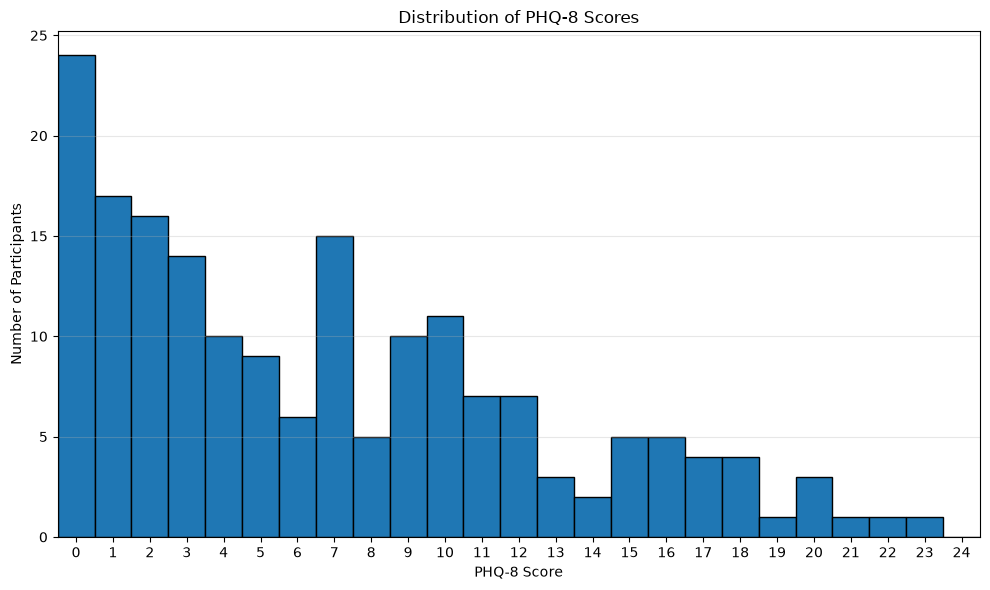

In [11]:
# ============================================================
# 6. PHQ-8 score histogram
# ============================================================

valid_phq8_scores = eda_df.loc[
    eda_df["PHQ8_Score"].between(0, 24, inclusive="both"),
    "PHQ8_Score",
].dropna()

plt.figure(figsize=(10, 6))

# Half-integer bin edges place each integer score in its own bin.
bins = [score - 0.5 for score in range(26)]

plt.hist(
    valid_phq8_scores,
    bins=bins,
    edgecolor="black",
)

plt.title("Distribution of PHQ-8 Scores")
plt.xlabel("PHQ-8 Score")
plt.ylabel("Number of Participants")
plt.xticks(range(0, 25))
plt.xlim(-0.5, 24.5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# 7. Data-quality summary
# ============================================================

print("\nMissing values:")
print(eda_df[required_columns].isna().sum())

print("\nPHQ8_Score summary:")
print(valid_phq8_scores.describe())

invalid_gender_count = int(
    (
        eda_df["Gender"].notna()
        & ~eda_df["Gender"].isin([0, 1])
    ).sum()
)

invalid_binary_count = int(
    (
        eda_df["PHQ8_Binary"].notna()
        & ~eda_df["PHQ8_Binary"].isin([0, 1])
    ).sum()
)

invalid_score_count = int(
    (
        eda_df["PHQ8_Score"].notna()
        & ~eda_df["PHQ8_Score"].between(
            0,
            24,
            inclusive="both",
        )
    ).sum()
)

print("\nInvalid-value counts:")
print(f"Gender values outside 0 or 1: {invalid_gender_count}")
print(
    "PHQ8_Binary values outside 0 or 1: "
    f"{invalid_binary_count}"
)
print(
    "PHQ8_Score values outside 0–24: "
    f"{invalid_score_count}"
)


Missing values:
Dataset        0
Gender         0
PHQ8_Binary    0
PHQ8_Score     0
dtype: int64

PHQ8_Score summary:
count    181.000000
mean       6.767956
std        5.825354
min        0.000000
25%        2.000000
50%        6.000000
75%       10.000000
max       23.000000
Name: PHQ8_Score, dtype: float64

Invalid-value counts:
Gender values outside 0 or 1: 0
PHQ8_Binary values outside 0 or 1: 0
PHQ8_Score values outside 0–24: 0


In [13]:
count_summary_df = pd.DataFrame({
    "Category": [
        "Dataset: train",
        "Dataset: dev",
        "Dataset: test",
        "Gender: 0",
        "Gender: 1",
        "PHQ8_Binary: 0",
        "PHQ8_Binary: 1",
    ],
    "Count": [
        dataset_counts.loc["train"],
        dataset_counts.loc["dev"],
        dataset_counts.loc["test"],
        gender_counts.loc[0],
        gender_counts.loc[1],
        phq8_binary_counts.loc[0],
        phq8_binary_counts.loc[1],
    ],
})

display(count_summary_df)

,Category,Count
0,Dataset: train,103
1,Dataset: dev,32
2,Dataset: test,46
3,Gender: 0,81
4,Gender: 1,100
5,PHQ8_Binary: 0,127
6,PHQ8_Binary: 1,54


### Speech Feature Analysis

In [3]:
df = pd.read_csv("DAICWOZ_speechfeatures.csv")

In [4]:
CORE_SPEECH_FEATURES = ["speaking_rate","articulation_rate","phonation_ratio","pause_rate","mean_pause_duration","mean_f0_hertz","std_f0_hertz","mean_intensity_db","std_intensity_db","range_ratio_intensity_db","mean_hnr_db","std_hnr_db","spectral_slope","spectral_tilt","cepstral_peak_prominence_mean","cepstral_peak_prominence_std","mean_f1_loc","std_f1_loc","mean_b1_loc","std_b1_loc","mean_f2_loc","std_f2_loc","mean_b2_loc","std_b2_loc","spectral_gravity","spectral_std_dev","spectral_skewness","spectral_kurtosis"]

In [17]:
def save_speech_feature_histograms(
    df: pd.DataFrame,
    feature_columns: list[str],
    output_dir: str | Path = "EDA/Speech Features",
    bins: int = 30,
):
    """
    Save histograms as 3x3 pages (9 histograms per PNG).
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    available_features = [
        feature
        for feature in feature_columns
        if feature in df.columns
    ]

    missing_features = sorted(
        set(feature_columns) - set(available_features)
    )

    if missing_features:
        print("Missing features:")
        for feature in missing_features:
            print(f"  - {feature}")

    plots_per_page = 9
    n_pages = math.ceil(len(available_features) / plots_per_page)

    for page in range(n_pages):

        start = page * plots_per_page
        end = min(start + plots_per_page, len(available_features))

        page_features = available_features[start:end]

        fig, axes = plt.subplots(
            3,
            3,
            figsize=(15, 15)
        )

        axes = axes.flatten()

        for ax, feature in zip(axes, page_features):

            values = pd.to_numeric(
                df[feature],
                errors="coerce"
            ).dropna()

            ax.hist(
                values,
                bins=bins,
                edgecolor="black",
            )

            ax.set_title(feature, fontsize=11)
            ax.set_xlabel("Value")
            ax.set_ylabel("Count")
            ax.grid(axis="y", alpha=0.3)

            if len(values) > 0:
                stats_text = (
                    f"n={len(values)}\n"
                    f"Mean={values.mean():.2f}\n"
                    f"Median={values.median():.2f}\n"
                    f"Std={values.std():.2f}"
                )

                ax.text(
                    0.98,
                    0.98,
                    stats_text,
                    transform=ax.transAxes,
                    ha="right",
                    va="top",
                    fontsize=8,
                    bbox=dict(
                        facecolor="white",
                        edgecolor="gray",
                        alpha=0.85,
                    ),
                )

        # Hide unused subplots on the last page
        for ax in axes[len(page_features):]:
            ax.set_visible(False)

        fig.suptitle(
            f"Speech Feature Histograms (Page {page + 1})",
            fontsize=16,
        )

        plt.tight_layout(rect=[0, 0, 1, 0.97])

        output_path = (
            output_dir
            / f"speech_feature_histograms_page_{page + 1}.png"
        )

        plt.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.close(fig)

        print(f"Saved {output_path}")

    print(
        f"\nFinished saving {n_pages} page(s) "
        f"to {output_dir.resolve()}"
    )

In [18]:
save_speech_feature_histograms(
    df=df,
    feature_columns=CORE_SPEECH_FEATURES,
    output_dir="EDA/Speech Features",
)

Saved EDA/Speech Features/speech_feature_histograms_page_1.png
Saved EDA/Speech Features/speech_feature_histograms_page_2.png
Saved EDA/Speech Features/speech_feature_histograms_page_3.png
Saved EDA/Speech Features/speech_feature_histograms_page_4.png

Finished saving 4 page(s) to /Users/sonalprasad/Documents/Thesis/EDA/Speech Features


### Correlation

In [27]:
def spearman_correlation_report(
    df: pd.DataFrame,
    feature_columns: list[str],
    target_column: str = "PHQ8_Score",
    output_dir: str | Path = "EDA/Correlations",
    strong_threshold: float = 0.70,
):
    """
    Perform Spearman correlation analysis for:

    1. Speech feature vs. target
    2. Speech feature vs. speech feature

    Saves:
        - spearman_target_correlations.csv
        - spearman_feature_correlation_matrix.csv
        - spearman_feature_pvalue_matrix.csv
        - spearman_feature_n_matrix.csv
        - spearman_highly_correlated_feature_pairs.csv
        - spearman_target_correlations.png
        - spearman_feature_correlation_heatmap.png

    Returns
    -------
    dict
        Dictionary containing all result DataFrames.
    """

    # ========================================================
    # 1. Create output directory
    # ========================================================

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # ========================================================
    # 2. Validate columns
    # ========================================================

    available_features = [
        feature
        for feature in feature_columns
        if feature in df.columns
    ]

    missing_features = [
        feature
        for feature in feature_columns
        if feature not in df.columns
    ]

    if missing_features:
        print("Missing features:")
        for feature in missing_features:
            print(f"  - {feature}")

    if target_column not in df.columns:
        raise KeyError(
            f"Target column '{target_column}' was not found in df."
        )

    if not available_features:
        raise ValueError(
            "None of the requested speech features were found in df."
        )

    # ========================================================
    # 3. Convert features and target to numeric
    # ========================================================

    analysis_df = df[
        available_features + [target_column]
    ].copy()

    for column in analysis_df.columns:
        analysis_df[column] = pd.to_numeric(
            analysis_df[column],
            errors="coerce",
        )

    # ========================================================
    # 4. Feature -> target Spearman correlations
    # ========================================================

    target_results = []

    for feature in available_features:

        pair_df = analysis_df[
            [feature, target_column]
        ].dropna()

        n = len(pair_df)

        feature_unique = pair_df[feature].nunique()
        target_unique = pair_df[target_column].nunique()

        if (
            n < 3
            or feature_unique < 2
            or target_unique < 2
        ):
            rho = np.nan
            p_value = np.nan

        else:
            rho, p_value = spearmanr(
                pair_df[feature].to_numpy(),
                pair_df[target_column].to_numpy(),
            )

        target_results.append(
            {
                "Feature": feature,
                "N": n,
                "Spearman_Rho": rho,
                "Absolute_Rho": (
                    abs(rho)
                    if pd.notna(rho)
                    else np.nan
                ),
                "P_Value": p_value,
            }
        )

    target_corr_df = pd.DataFrame(target_results)

    target_corr_df = target_corr_df.sort_values(
        "Absolute_Rho",
        ascending=False,
        na_position="last",
    ).reset_index(drop=True)

    # ========================================================
    # 5. Add correlation-strength labels
    # ========================================================

    def correlation_strength(rho):

        if pd.isna(rho):
            return "Undefined"

        absolute_rho = abs(rho)

        if absolute_rho < 0.10:
            return "Negligible"

        elif absolute_rho < 0.30:
            return "Weak"

        elif absolute_rho < 0.50:
            return "Moderate"

        elif absolute_rho < 0.70:
            return "Strong"

        else:
            return "Very strong"

    target_corr_df["Strength"] = (
        target_corr_df["Spearman_Rho"]
        .apply(correlation_strength)
    )

    target_corr_df["Significant_p05"] = (
        target_corr_df["P_Value"] < 0.05
    )

    # Save target correlation results
    target_corr_df.to_csv(
        output_dir / "spearman_target_correlations.csv",
        index=False,
    )

    # ========================================================
    # 6. Initialize feature-feature matrices
    # ========================================================

    feature_corr_matrix = pd.DataFrame(
        np.nan,
        index=available_features,
        columns=available_features,
        dtype=float,
    )

    feature_pvalue_matrix = pd.DataFrame(
        np.nan,
        index=available_features,
        columns=available_features,
        dtype=float,
    )

    feature_n_matrix = pd.DataFrame(
        np.nan,
        index=available_features,
        columns=available_features,
        dtype=float,
    )

    # ========================================================
    # 7. Feature -> feature Spearman correlations
    #
    # Compute only upper triangle and mirror it.
    # This avoids calculating the same pair twice.
    # ========================================================

    for i, feature_1 in enumerate(available_features):

        for j in range(i, len(available_features)):

            feature_2 = available_features[j]

            # ------------------------------------------------
            # Diagonal
            # ------------------------------------------------

            if feature_1 == feature_2:

                values = analysis_df[
                    feature_1
                ].dropna()

                n = len(values)

                if (
                    n >= 2
                    and values.nunique() >= 2
                ):
                    rho = 1.0

                    # p-value for self-correlation is not
                    # inferentially meaningful, so NaN is cleaner.
                    p_value = np.nan

                else:
                    rho = np.nan
                    p_value = np.nan

            # ------------------------------------------------
            # Different features
            # ------------------------------------------------

            else:

                pair_df = analysis_df[
                    [feature_1, feature_2]
                ].dropna()

                n = len(pair_df)

                feature_1_unique = (
                    pair_df[feature_1].nunique()
                )

                feature_2_unique = (
                    pair_df[feature_2].nunique()
                )

                if (
                    n < 3
                    or feature_1_unique < 2
                    or feature_2_unique < 2
                ):
                    rho = np.nan
                    p_value = np.nan

                else:
                    rho, p_value = spearmanr(
                        pair_df[
                            feature_1
                        ].to_numpy(),
                        pair_df[
                            feature_2
                        ].to_numpy(),
                    )

            # ------------------------------------------------
            # Store upper triangle
            # ------------------------------------------------

            feature_corr_matrix.loc[
                feature_1,
                feature_2,
            ] = rho

            feature_pvalue_matrix.loc[
                feature_1,
                feature_2,
            ] = p_value

            feature_n_matrix.loc[
                feature_1,
                feature_2,
            ] = n

            # ------------------------------------------------
            # Mirror to lower triangle
            # ------------------------------------------------

            feature_corr_matrix.loc[
                feature_2,
                feature_1,
            ] = rho

            feature_pvalue_matrix.loc[
                feature_2,
                feature_1,
            ] = p_value

            feature_n_matrix.loc[
                feature_2,
                feature_1,
            ] = n

    # ========================================================
    # 8. Save feature-feature matrices
    # ========================================================

    feature_corr_matrix.to_csv(
        output_dir
        / "spearman_feature_correlation_matrix.csv"
    )

    feature_pvalue_matrix.to_csv(
        output_dir
        / "spearman_feature_pvalue_matrix.csv"
    )

    feature_n_matrix.to_csv(
        output_dir
        / "spearman_feature_n_matrix.csv"
    )

    # ========================================================
    # 9. Highly correlated feature pairs
    # ========================================================

    highly_correlated_pairs = []

    for i in range(len(available_features)):

        for j in range(
            i + 1,
            len(available_features),
        ):

            feature_1 = available_features[i]
            feature_2 = available_features[j]

            rho = feature_corr_matrix.loc[
                feature_1,
                feature_2,
            ]

            p_value = (
                feature_pvalue_matrix.loc[
                    feature_1,
                    feature_2,
                ]
            )

            n = feature_n_matrix.loc[
                feature_1,
                feature_2,
            ]

            if (
                pd.notna(rho)
                and abs(rho) >= strong_threshold
            ):
                highly_correlated_pairs.append(
                    {
                        "Feature_1": feature_1,
                        "Feature_2": feature_2,
                        "N": int(n),
                        "Spearman_Rho": rho,
                        "Absolute_Rho": abs(rho),
                        "P_Value": p_value,
                        "Significant_p05": (
                            bool(p_value < 0.05)
                            if pd.notna(p_value)
                            else False
                        ),
                    }
                )

    high_corr_df = pd.DataFrame(
        highly_correlated_pairs
    )

    if not high_corr_df.empty:

        high_corr_df = high_corr_df.sort_values(
            "Absolute_Rho",
            ascending=False,
        ).reset_index(drop=True)

    else:
        high_corr_df = pd.DataFrame(
            columns=[
                "Feature_1",
                "Feature_2",
                "N",
                "Spearman_Rho",
                "Absolute_Rho",
                "P_Value",
                "Significant_p05",
            ]
        )

    high_corr_df.to_csv(
        output_dir
        / "spearman_highly_correlated_feature_pairs.csv",
        index=False,
    )

    # ========================================================
    # 10. Target-correlation bar plot
    # ========================================================

    plot_df = target_corr_df.dropna(
        subset=["Spearman_Rho"]
    ).copy()

    plot_df = plot_df.sort_values(
        "Spearman_Rho"
    )

    plt.figure(
        figsize=(
            10,
            max(8, len(plot_df) * 0.35),
        )
    )

    plt.barh(
        plot_df["Feature"],
        plot_df["Spearman_Rho"],
    )

    plt.axvline(
        0,
        linewidth=1,
    )

    plt.xlabel("Spearman correlation (ρ)")
    plt.ylabel("Speech Feature")

    plt.title(
        f"Spearman Correlation with {target_column}"
    )

    plt.tight_layout()

    plt.savefig(
        output_dir
        / "spearman_target_correlations.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # ========================================================
    # 11. Feature correlation heatmap
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(16, 14)
    )

    image = ax.imshow(
        feature_corr_matrix.to_numpy(
            dtype=float
        ),
        vmin=-1,
        vmax=1,
        aspect="auto",
    )

    ax.set_xticks(
        range(len(available_features))
    )

    ax.set_yticks(
        range(len(available_features))
    )

    ax.set_xticklabels(
        available_features,
        rotation=90,
        fontsize=8,
    )

    ax.set_yticklabels(
        available_features,
        fontsize=8,
    )

    ax.set_title(
        "Spearman Correlation Matrix: Speech Features"
    )

    colorbar = fig.colorbar(
        image,
        ax=ax,
    )

    colorbar.set_label(
        "Spearman correlation (ρ)"
    )

    plt.tight_layout()

    plt.savefig(
        output_dir
        / "spearman_feature_correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    # ========================================================
    # 12. Print summary
    # ========================================================

    print("\n======================================")
    print("SPEARMAN CORRELATION REPORT")
    print("======================================")

    print(
        f"\nTarget: {target_column}"
    )

    print(
        f"Number of speech features: "
        f"{len(available_features)}"
    )

    print("\nTop correlations with target:")

    print(
        target_corr_df[
            [
                "Feature",
                "N",
                "Spearman_Rho",
                "P_Value",
                "Strength",
                "Significant_p05",
            ]
        ]
        .head(10)
        .to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}",
        )
    )

    print(
        "\nHighly correlated speech-feature pairs "
        f"(|ρ| >= {strong_threshold}): "
        f"{len(high_corr_df)}"
    )

    if not high_corr_df.empty:

        print(
            high_corr_df[
                [
                    "Feature_1",
                    "Feature_2",
                    "N",
                    "Spearman_Rho",
                    "P_Value",
                    "Significant_p05",
                ]
            ]
            .head(20)
            .to_string(
                index=False,
                float_format=lambda x: f"{x:.4f}",
            )
        )

    print(
        f"\nReports saved to:\n"
        f"{output_dir.resolve()}"
    )

    # ========================================================
    # 13. Return results
    # ========================================================

    return {
        "target_correlations": (
            target_corr_df
        ),
        "feature_correlation_matrix": (
            feature_corr_matrix
        ),
        "feature_pvalue_matrix": (
            feature_pvalue_matrix
        ),
        "feature_n_matrix": (
            feature_n_matrix
        ),
        "highly_correlated_pairs": (
            high_corr_df
        ),
    }

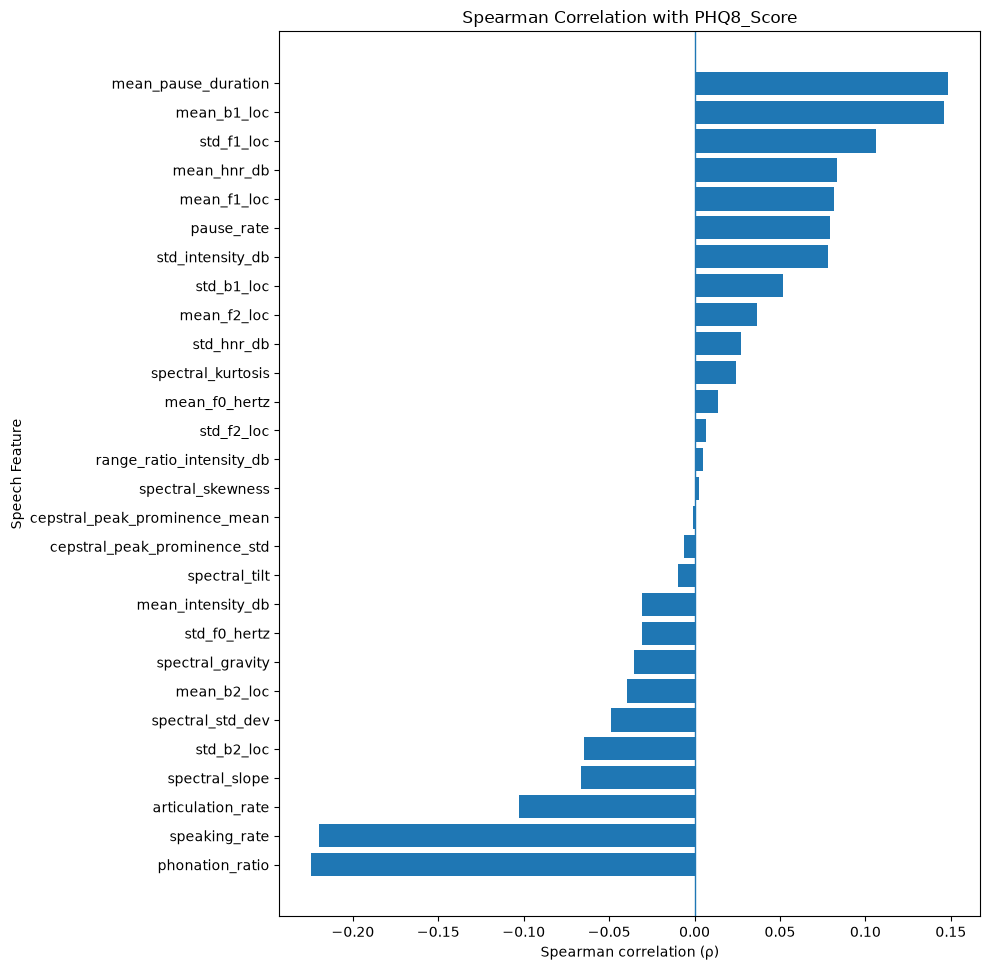

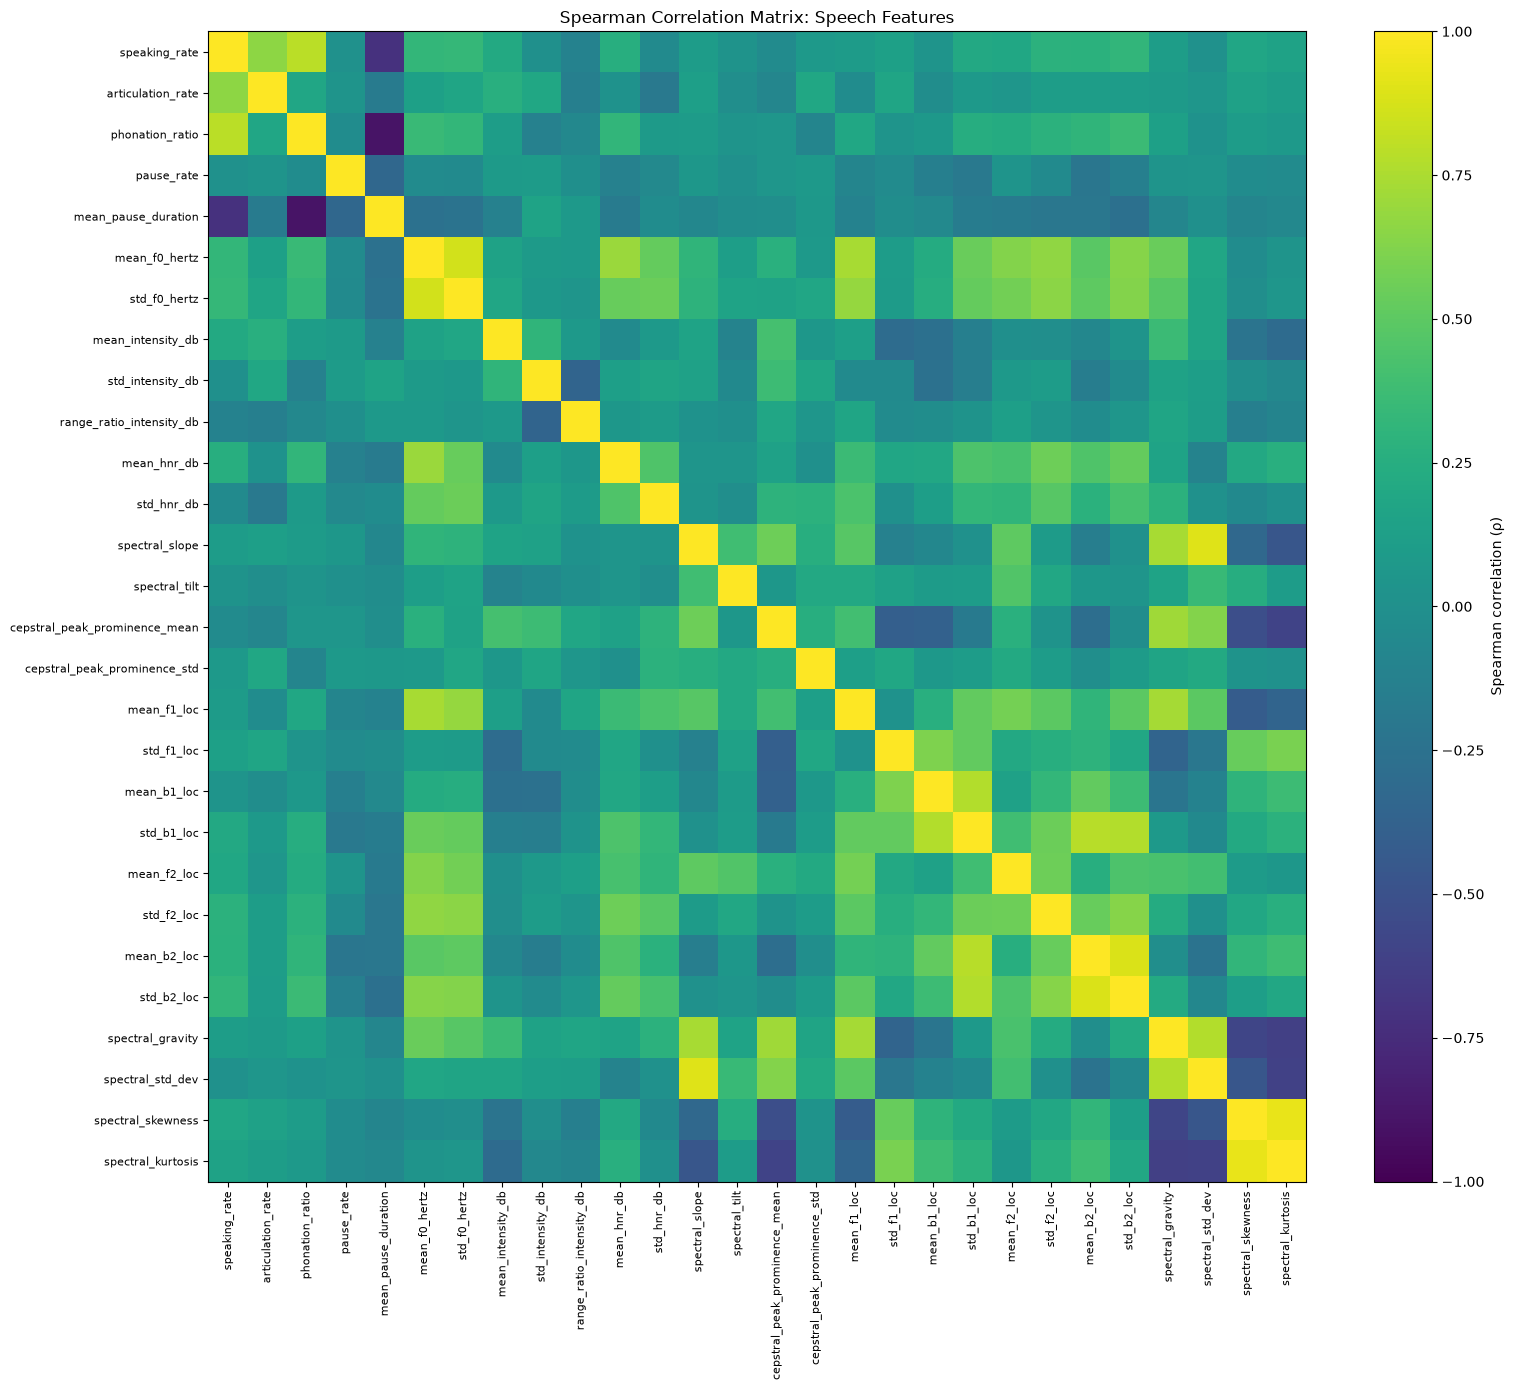


SPEARMAN CORRELATION REPORT

Target: PHQ8_Score
Number of speech features: 28

Top correlations with target:
            Feature   N  Spearman_Rho  P_Value   Strength  Significant_p05
    phonation_ratio 181       -0.2244   0.0024       Weak             True
      speaking_rate 181       -0.2197   0.0030       Weak             True
mean_pause_duration 181        0.1484   0.0461       Weak             True
        mean_b1_loc 181        0.1461   0.0497       Weak             True
         std_f1_loc 181        0.1063   0.1543       Weak            False
  articulation_rate 181       -0.1029   0.1681       Weak            False
        mean_hnr_db 181        0.0833   0.2652 Negligible            False
        mean_f1_loc 181        0.0815   0.2757 Negligible            False
         pause_rate 181        0.0794   0.2878 Negligible            False
   std_intensity_db 181        0.0779   0.2974 Negligible            False

Highly correlated speech-feature pairs (|ρ| >= 0.7): 15
        

In [28]:
spearman_results = spearman_correlation_report(
    df=df,
    feature_columns=CORE_SPEECH_FEATURES,
    target_column="PHQ8_Score",
    output_dir="EDA/Spearman Correlations",
    strong_threshold=0.70,
)

In [29]:
display(spearman_results["target_correlations"])

,Feature,N,Spearman_Rho,Absolute_Rho,P_Value,Strength,Significant_p05
0,phonation_ratio,181,-0.224380,0.224380,0.002392,Weak,True
1,speaking_rate,181,-0.219714,0.219714,0.002960,Weak,True
2,mean_pause_duration,181,0.148426,0.148426,0.046142,Weak,True
3,mean_b1_loc,181,0.146122,0.146122,0.049670,Weak,True
4,std_f1_loc,181,0.106326,0.106326,0.154274,Weak,False
5,articulation_rate,181,-0.102890,0.102890,0.168104,Weak,False
6,mean_hnr_db,181,0.083258,0.083258,0.265153,Negligible,False
7,mean_f1_loc,181,0.081450,0.081450,0.275703,Negligible,False
8,pause_rate,181,0.079440,0.079440,0.287766,Negligible,False
9,std_intensity_db,181,0.077867,0.077867,0.297449,Negligible,False


In [30]:
display(spearman_results["highly_correlated_pairs"])

,Feature_1,Feature_2,N,Spearman_Rho,Absolute_Rho,P_Value,Significant_p05
0,spectral_skewness,spectral_kurtosis,181,0.933248,0.933248,1.646862e-81,True
1,spectral_slope,spectral_std_dev,181,0.904171,0.904171,4.963579e-68,True
2,phonation_ratio,mean_pause_duration,181,-0.895224,0.895224,9.696342e-65,True
3,mean_b2_loc,std_b2_loc,181,0.890324,0.890324,4.619337e-63,True
4,mean_f0_hertz,std_f0_hertz,181,0.866553,0.866553,6.448765e-56,True
5,speaking_rate,phonation_ratio,181,0.794173,0.794173,1.421948e-40,True
6,std_b1_loc,mean_b2_loc,181,0.785688,0.785688,3.494988e-39,True
7,mean_b1_loc,std_b1_loc,181,0.773118,0.773118,3.098288e-37,True
8,spectral_gravity,spectral_std_dev,181,0.771568,0.771568,5.280281e-37,True
9,std_b1_loc,std_b2_loc,181,0.766074,0.766074,3.379304e-36,True


In [34]:
def save_speech_feature_boxplots(
    df: pd.DataFrame,
    feature_columns: list[str],
    output_dir: str | Path = "EDA/Boxplots",
    show_plots: bool = True,
):
    """
    Create boxplots for speech features with 12 plots per page.

    Layout:
        4 rows x 3 columns = 12 plots per page

    Saves:
        speech_feature_boxplots_page_1.png
        speech_feature_boxplots_page_2.png
        ...
    """

    # ========================================================
    # 1. Create output directory
    # ========================================================

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    # ========================================================
    # 2. Check which features are available
    # ========================================================

    available_features = [
        feature
        for feature in feature_columns
        if feature in df.columns
    ]

    missing_features = [
        feature
        for feature in feature_columns
        if feature not in df.columns
    ]

    if missing_features:
        print("Missing features:")

        for feature in missing_features:
            print(f"  - {feature}")

    if not available_features:
        raise ValueError(
            "None of the requested speech features "
            "were found in the DataFrame."
        )

    # ========================================================
    # 3. Page configuration
    # ========================================================

    plots_per_page = 12

    n_rows = 4
    n_cols = 3

    n_pages = math.ceil(
        len(available_features) / plots_per_page
    )

    # ========================================================
    # 4. Generate each page
    # ========================================================

    for page in range(n_pages):

        start = page * plots_per_page

        end = min(
            start + plots_per_page,
            len(available_features),
        )

        page_features = available_features[
            start:end
        ]

        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(15, 16),
        )

        axes = axes.flatten()

        # ====================================================
        # Plot each feature
        # ====================================================

        for ax, feature in zip(
            axes,
            page_features,
        ):

            values = pd.to_numeric(
                df[feature],
                errors="coerce",
            ).dropna()

            # -----------------------------------------------
            # Boxplot
            # -----------------------------------------------

            ax.boxplot(
                values,
                vert=True,
                showfliers=True,
            )

            ax.set_title(
                feature,
                fontsize=11,
            )

            ax.set_ylabel("Value")

            ax.set_xticks([])

            ax.grid(
                axis="y",
                alpha=0.3,
            )

            # -----------------------------------------------
            # Calculate summary statistics
            # -----------------------------------------------

            if len(values) > 0:

                q1 = values.quantile(0.25)
                median = values.median()
                q3 = values.quantile(0.75)

                iqr = q3 - q1

                lower_bound = q1 - (1.5 * iqr)
                upper_bound = q3 + (1.5 * iqr)

                outlier_count = (
                    (
                        (values < lower_bound)
                        | (values > upper_bound)
                    )
                    .sum()
                )

                stats_text = (
                    f"n={len(values)}\n"
                    f"Q1={q1:.2f}\n"
                    f"Median={median:.2f}\n"
                    f"Q3={q3:.2f}\n"
                    f"IQR={iqr:.2f}\n"
                    f"Outliers={outlier_count}"
                )

                ax.text(
                    0.98,
                    0.98,
                    stats_text,
                    transform=ax.transAxes,
                    ha="right",
                    va="top",
                    fontsize=8,
                    bbox=dict(
                        facecolor="white",
                        edgecolor="gray",
                        alpha=0.85,
                    ),
                )

        # ====================================================
        # 5. Hide unused plots on final page
        # ====================================================

        for ax in axes[
            len(page_features):
        ]:
            ax.set_visible(False)

        # ====================================================
        # 6. Page title
        # ====================================================

        fig.suptitle(
            (
                "Speech Feature Boxplots "
                f"(Page {page + 1})"
            ),
            fontsize=16,
        )

        plt.tight_layout(
            rect=[0, 0, 1, 0.97]
        )

        # ====================================================
        # 7. Save PNG
        # ====================================================

        output_path = (
            output_dir
            / (
                "speech_feature_boxplots_"
                f"page_{page + 1}.png"
            )
        )

        plt.savefig(
            output_path,
            dpi=300,
            bbox_inches="tight",
        )

        print(
            f"Saved: {output_path}"
        )

        # ====================================================
        # 8. Display or close
        # ====================================================

        if show_plots:
            plt.show()

        plt.close(fig)

    print(
        f"\nFinished creating {n_pages} "
        "boxplot page(s)."
    )

    print(
        f"Saved to:\n{output_dir.resolve()}"
    )

from pathlib import Path

import pandas as pd


def summarize_speech_feature_outliers(
    df: pd.DataFrame,
    feature_columns: list[str],
    output_dir: str | Path = "EDA/Speech Features",
):
    """
    Summarize outliers for each speech feature using the
    standard boxplot rule (1.5 × IQR).

    Saves:
        speech_feature_outlier_summary.csv
    """

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    summary = []

    for feature in feature_columns:

        if feature not in df.columns:
            continue

        values = (
            pd.to_numeric(
                df[feature],
                errors="coerce",
            )
            .dropna()
        )

        if len(values) == 0:
            continue

        q1 = values.quantile(0.25)
        median = values.median()
        q3 = values.quantile(0.75)

        iqr = q3 - q1

        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)

        low_outlier_mask = values < lower_bound
        high_outlier_mask = values > upper_bound

        low_outlier_count = int(
            low_outlier_mask.sum()
        )

        high_outlier_count = int(
            high_outlier_mask.sum()
        )

        outlier_count = (
            low_outlier_count
            + high_outlier_count
        )

        outlier_percent = (
            100 * outlier_count / len(values)
        )

        summary.append(
            {
                "Feature": feature,
                "N": len(values),

                "Q1": q1,
                "Median": median,
                "Q3": q3,
                "IQR": iqr,

                "Lower_Bound": lower_bound,
                "Upper_Bound": upper_bound,

                "Low_Outlier_Count":
                    low_outlier_count,

                "High_Outlier_Count":
                    high_outlier_count,

                "Outlier_Count":
                    outlier_count,

                "Outlier_Percent":
                    outlier_percent,
            }
        )

    summary_df = pd.DataFrame(summary)

    summary_df = summary_df.sort_values(
        by="Outlier_Count",
        ascending=False,
    ).reset_index(drop=True)

    output_path = (
        "EDA/Boxplots/speech_feature_outlier_summary.csv"
    )

    summary_df.to_csv(
        output_path,
        index=False,
    )

    print(summary_df)

    print(
        f"\nSaved to:\n{output_path.resolve()}"
    )

    return summary_df

/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} ins

Saved: EDA/Boxplots/speech_feature_boxplots_page_1.png


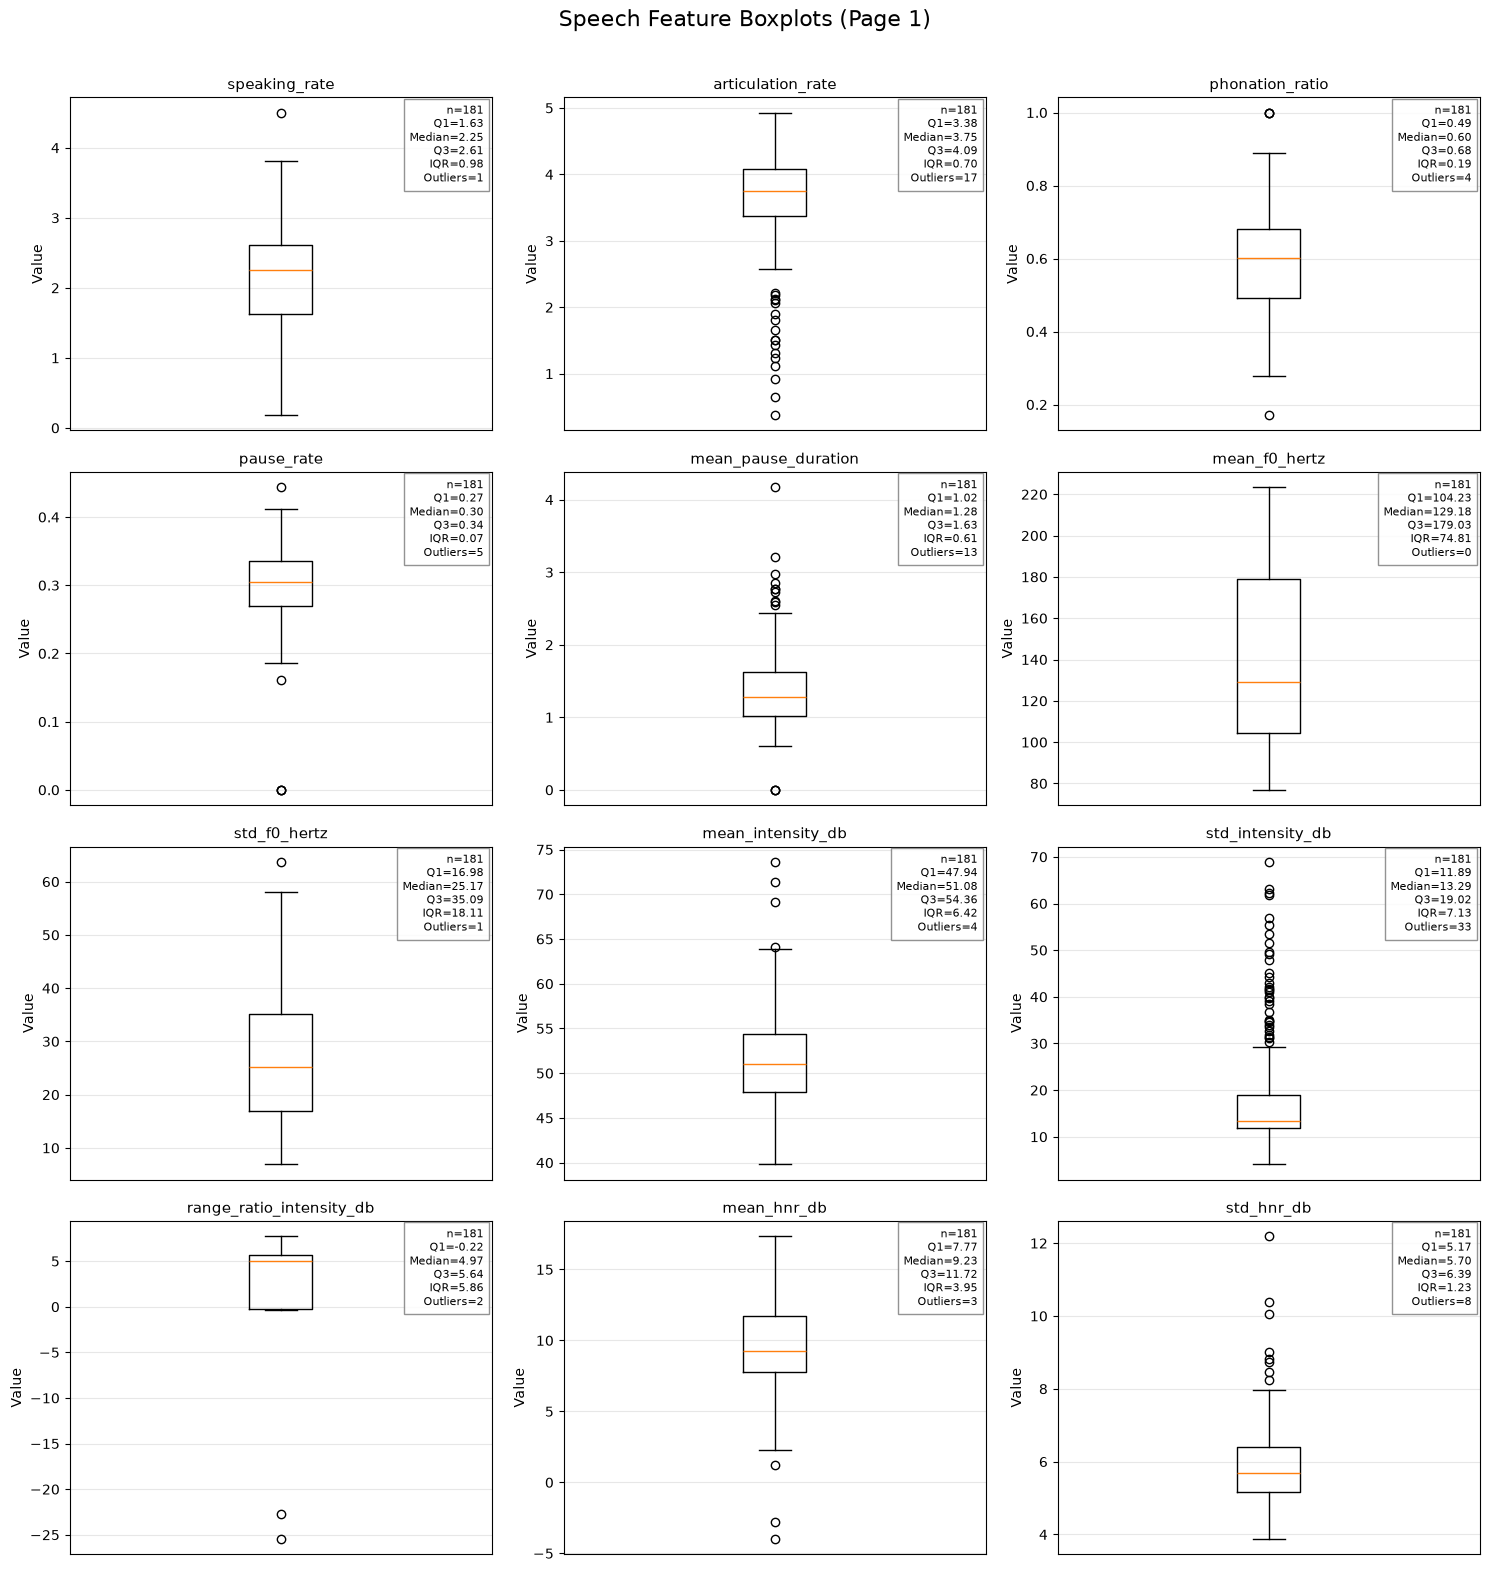

/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} ins

Saved: EDA/Boxplots/speech_feature_boxplots_page_2.png


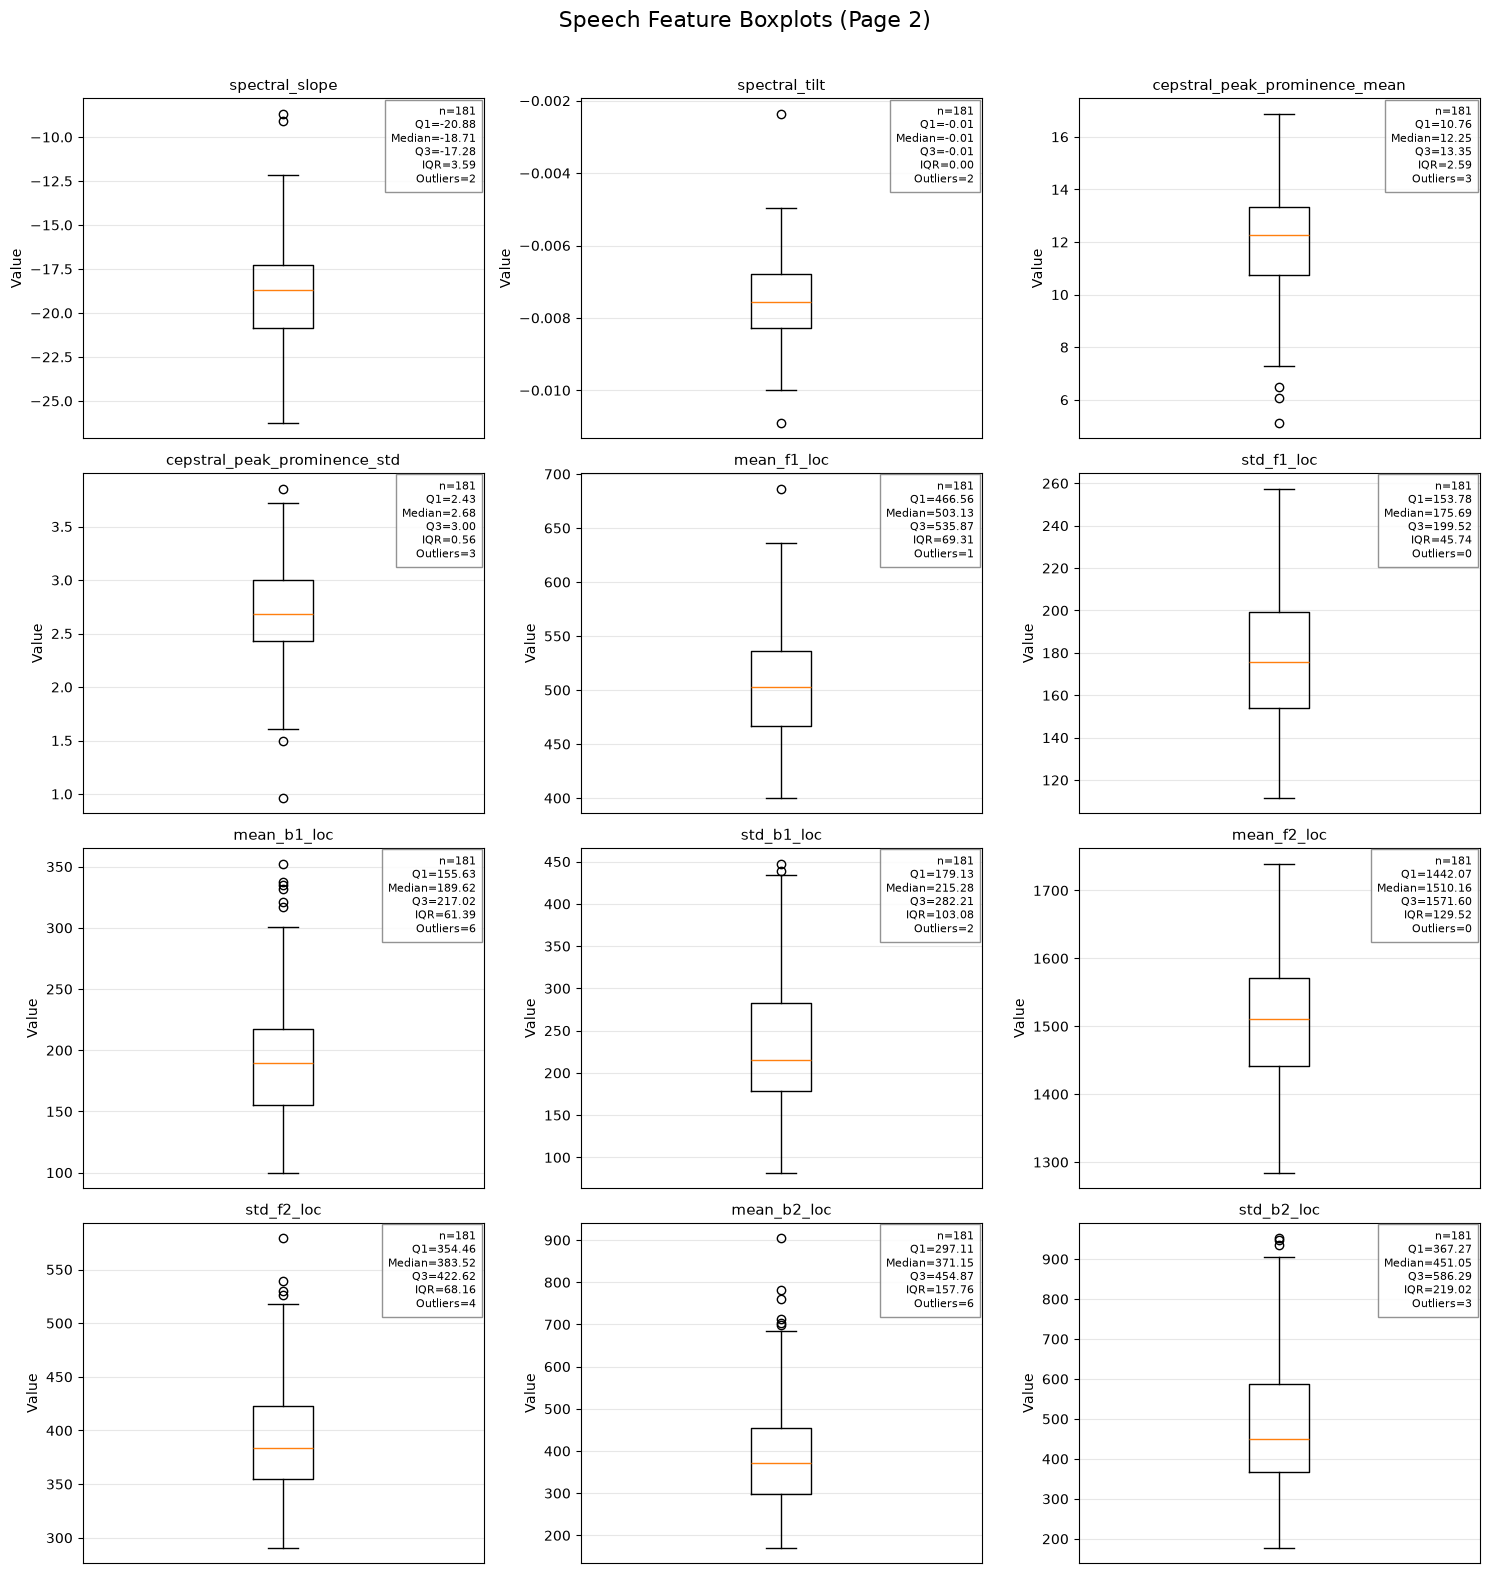

/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/var/folders/0n/sk_kqkr10xl98f_9d5t_82m00000gn/T/ipykernel_50283/2577047857.py:114: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} ins

Saved: EDA/Boxplots/speech_feature_boxplots_page_3.png


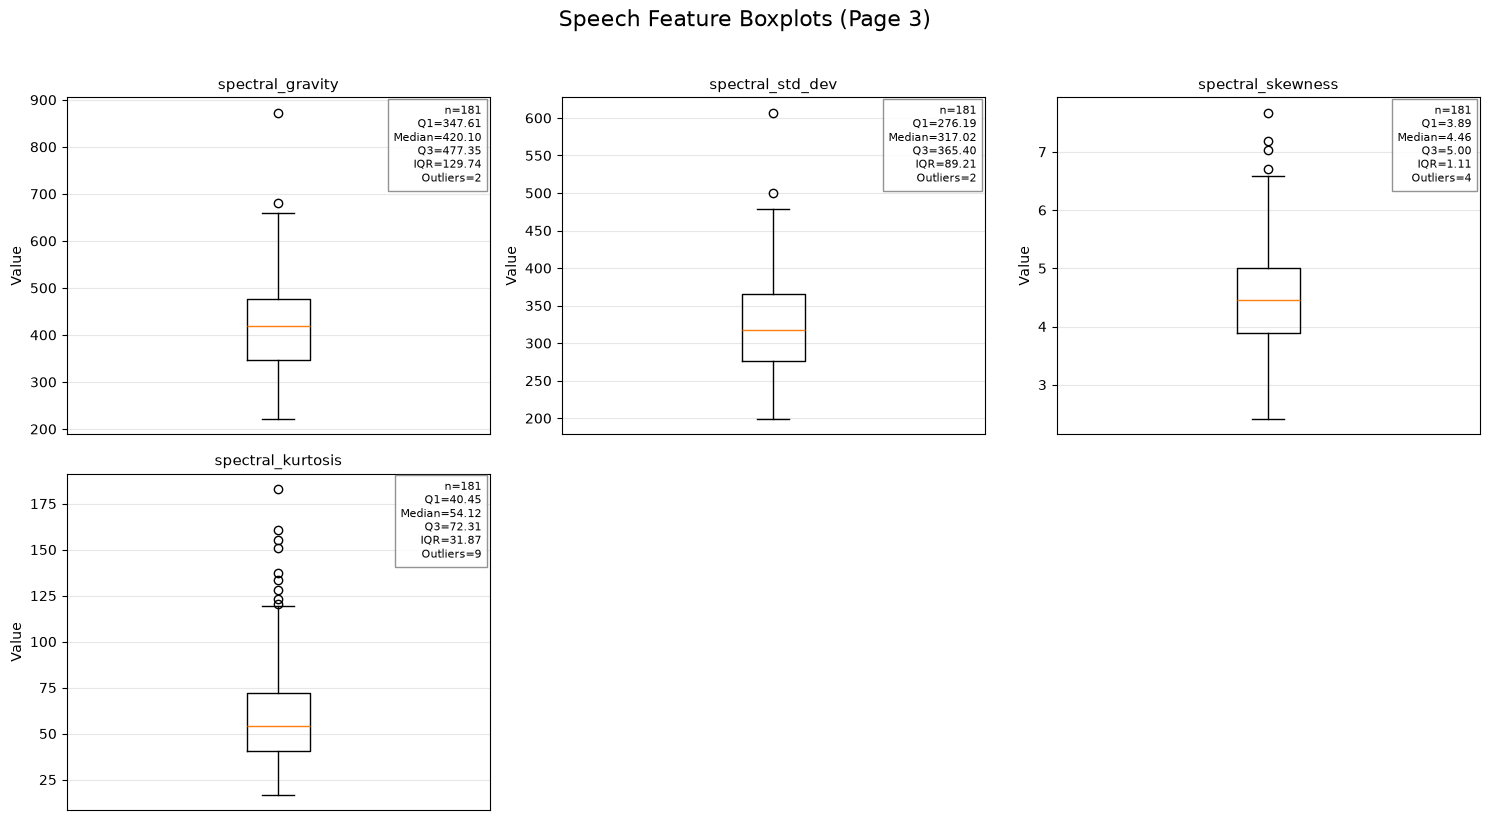


Finished creating 3 boxplot page(s).
Saved to:
/Users/sonalprasad/Documents/Thesis/EDA/Boxplots


In [33]:
save_speech_feature_boxplots(
    df=df,
    feature_columns=CORE_SPEECH_FEATURES,
    output_dir="EDA/Boxplots",
)

In [35]:
outlier_summary = summarize_speech_feature_outliers(
    df=df,
    feature_columns=CORE_SPEECH_FEATURES,
)

                          Feature    N           Q1       Median           Q3  \
0                std_intensity_db  181    11.888511    13.287288    19.023435   
1               articulation_rate  181     3.380796     3.751459     4.085586   
2             mean_pause_duration  181     1.018290     1.282332     1.625200   
3               spectral_kurtosis  181    40.446536    54.116189    72.313277   
4                      std_hnr_db  181     5.168691     5.695292     6.394124   
5                     mean_b2_loc  181   297.106298   371.151317   454.865335   
6                     mean_b1_loc  181   155.626008   189.622308   217.020785   
7                      pause_rate  181     0.269079     0.304512     0.336192   
8                 phonation_ratio  181     0.490966     0.601443     0.681513   
9               spectral_skewness  181     3.889998     4.462971     5.003931   
10              mean_intensity_db  181    47.941963    51.083362    54.364479   
11                     std_f

### 3 Features vs. Depression Severity (Outlier Analysis)

In [5]:
from statsmodels.nonparametric.smoothers_lowess import lowess

def plot_feature_vs_phq8_outliers(
    df: pd.DataFrame,
    feature_columns: list[str],
    participant_column: str = "Participant_ID",
    target_column: str = "PHQ8_Score",
    output_dir: str | Path = "EDA/Outlier Analysis",
):
    """
    Create scatterplots showing speech feature values versus PHQ-8.

    Two figures are created for each feature:
        1) without participant IDs
        2) with participant IDs on outliers only

    Also saves a CSV listing every detected outlier.
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    outlier_rows = []

    for feature in feature_columns:

        if feature not in df.columns:
            print(f"Skipping {feature}: not found.")
            continue

        working_df = df[
            [
                participant_column,
                target_column,
                feature,
            ]
        ].copy()

        working_df[target_column] = pd.to_numeric(
            working_df[target_column],
            errors="coerce",
        )

        working_df[feature] = pd.to_numeric(
            working_df[feature],
            errors="coerce",
        )

        working_df = working_df.dropna()

        # ---------------------------------------------
        # Calculate boxplot outlier thresholds
        # ---------------------------------------------

        q1 = working_df[feature].quantile(0.25)
        q3 = working_df[feature].quantile(0.75)

        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        working_df["Outlier_Type"] = "Normal"

        working_df.loc[
            working_df[feature] < lower_bound,
            "Outlier_Type",
        ] = "Low"

        working_df.loc[
            working_df[feature] > upper_bound,
            "Outlier_Type",
        ] = "High"

        # Save outlier table

        feature_outliers = working_df.loc[
            working_df["Outlier_Type"] != "Normal"
        ].copy()

        feature_outliers.insert(
            0,
            "Feature",
            feature,
        )

        outlier_rows.append(feature_outliers)

        # ---------------------------------------------------
        # Create BOTH versions of the figure
        # ---------------------------------------------------

        for show_ids in [False, True]:

            fig, ax = plt.subplots(
                figsize=(9, 6)
            )

            # --------------------------
            # Normal observations
            # --------------------------

            normal = working_df[
                working_df["Outlier_Type"] == "Normal"
            ]

            ax.scatter(
                normal[target_column],
                normal[feature],
                s=40,
                alpha=0.7,
                label="Normal",
            )

            # --------------------------
            # Low outliers
            # --------------------------

            low = working_df[
                working_df["Outlier_Type"] == "Low"
            ]

            ax.scatter(
                low[target_column],
                low[feature],
                marker="^",
                s=90,
                label="Low Outlier",
            )

            # --------------------------
            # High outliers
            # --------------------------

            high = working_df[
                working_df["Outlier_Type"] == "High"
            ]

            ax.scatter(
                high[target_column],
                high[feature],
                marker="D",
                s=90,
                label="High Outlier",
            )

            # --------------------------
            # LOWESS trend line
            # --------------------------

            if len(working_df) >= 5:

                smoothed = lowess(
                    working_df[feature],
                    working_df[target_column],
                    frac=0.40,
                    return_sorted=True,
                )

                ax.plot(
                    smoothed[:, 0],
                    smoothed[:, 1],
                    linewidth=2,
                    label="LOWESS",
                )

            # --------------------------
            # Outlier thresholds
            # --------------------------

            ax.axhline(
                lower_bound,
                linestyle="--",
                linewidth=1,
                label="Lower Outlier Threshold",
            )

            ax.axhline(
                upper_bound,
                linestyle="--",
                linewidth=1,
                label="Upper Outlier Threshold",
            )

            # --------------------------
            # Annotate outliers
            # --------------------------

            if show_ids:

                for _, row in feature_outliers.iterrows():

                    ax.annotate(
                        str(row[participant_column]),
                        (
                            row[target_column],
                            row[feature],
                        ),
                        xytext=(5, 5),
                        textcoords="offset points",
                        fontsize=8,
                    )

            ax.set_xlabel("PHQ-8 Score")
            ax.set_ylabel(feature)

            title = (
                f"{feature} vs PHQ-8 Score"
            )

            if show_ids:
                title += " (Participant IDs)"

            ax.set_title(title)

            ax.grid(alpha=0.3)

            ax.legend()

            plt.tight_layout()

            filename = (
                f"{feature}_vs_PHQ8"
            )

            if show_ids:
                filename += "_with_ids"

            filename += ".png"

            plt.savefig(
                output_dir / filename,
                dpi=300,
                bbox_inches="tight",
            )

            plt.close(fig)

    # -------------------------------------------------------
    # Save outlier CSV
    # -------------------------------------------------------

    if outlier_rows:

        outlier_df = pd.concat(
            outlier_rows,
            ignore_index=True,
        )

        outlier_df.to_csv(
            output_dir
            / "feature_outlier_participants.csv",
            index=False,
        )

        print(
            f"Saved outlier table with "
            f"{len(outlier_df)} rows."
        )

    print(
        f"\nFinished.\nOutput folder:\n"
        f"{output_dir.resolve()}"
    )

In [6]:
plot_feature_vs_phq8_outliers(
    df=df,
    feature_columns=[
        "std_intensity_db",
        "articulation_rate",
        "mean_pause_duration",
    ],
)

Saved outlier table with 63 rows.

Finished.
Output folder:
/Users/sonalprasad/Documents/Thesis/EDA/Outlier Analysis
